# Food Orders Dataset: Data Understanding, Transformation & Validation
**Student Practical Assignment** | **Dataset:** `food_orders.csv`

---

### Business Scenario
You are a junior data analyst/data engineer at an online food-delivery company. The operations team has shared a CSV file containing order, customer, restaurant, payment, delivery, refund, weather, and order-channel information. Before the company can use this data for reporting, you must understand its structure, identify data-quality issues, clean and transform it, validate the results, and summarize useful business insights.

### Working Rules Followed
* Original data is preserved in `raw_df`; transformations are performed on `work_df`.
* Markdown explanations accompany all critical steps.
* Missing values are treated with domain rigor (missing refunds/offers are not blindly zeroed; missing payments are labeled `'Unknown'`; missing offers are labeled `'Not Specified'`).
* All derived metrics and data quality assertions are documented.


---
## Task 1 — Load and Understand the Dataset

In this task, we load the required Python libraries, ingest `food_orders.csv` into `raw_df`, inspect its structure, view head/tail/sample distributions, and describe what each column represents.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display options
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

# 1. & 2. Load food_orders.csv into raw_df
raw_df = pd.read_csv('food_orders.csv')
print(f"Dataset successfully loaded. Shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")


Dataset successfully loaded. Shape: 1010 rows x 14 columns


In [ ]:
# 3. Display first 5 rows, last 5 rows, and a sample of 5 rows
print("--- FIRST 5 ROWS ---")
display(raw_df.head(5))

print("--- LAST 5 ROWS ---")
display(raw_df.tail(5))

print("--- SAMPLE 5 ROWS ---")
display(raw_df.sample(5, random_state=42))


--- FIRST 5 ROWS ---
   Order ID Customer ID Restaurant ID  Order Date and Time Delivery Date and Time  Order Value  Delivery Fee    Payment Method Discounts and Offers  Commission Fee  Payment Processing Fee  Refunds/Chargebacks Weather Condition Order Channel
0         1       C8270         R2924  2024-02-01 01:11:52    2024-02-01 02:39:52       1914.0           0.0       Credit Card            5% on App           150.0                    47.0                  0.0             Rainy    Mobile App
1         2       C1860         R2054  2024-02-02 22:11:04    2024-02-02 22:46:04        986.0          40.0    Digital Wallet                  10%           198.0                    23.0                  0.0            Cloudy    Mobile App
2         3       C6390         R2870  2024-01-31 05:54:35    2024-01-31 06:52:35        937.0          30.0  Cash on Delivery         15% New User           195.0                    45.0                  0.0             Humid    Mobile App
3         4    

In [ ]:
# 4. & 5. Structure, column names, data types, and statistical summaries
print("--- DATASET INFO ---")
raw_df.info()

print("
--- NUMERICAL SUMMARY ---")
display(raw_df.describe())

print("
--- CATEGORICAL SUMMARY ---")
display(raw_df.describe(include=['object']))


--- NUMERICAL SUMMARY ---
          Order ID  Order Value  Delivery Fee  Commission Fee  Payment Processing Fee  Refunds/Chargebacks
count  1010.000000   969.000000    960.000000      970.000000              959.000000           970.000000
mean    499.221782  1055.901961     28.625000      127.042268               29.895725            27.886598
std     288.589479   529.534182     16.927281       43.013345               11.731583            49.383898
min       1.000000   104.000000      0.000000       50.000000               10.000000             0.000000
25%     248.250000   600.000000     20.000000       90.250000               20.000000             0.000000
50%     498.500000  1041.000000     30.000000      128.000000               30.000000             0.000000
75%     748.750000  1494.000000     40.000000      164.000000               40.000000            50.000000
max    1000.000000  1995.000000     50.000000      200.000000               50.000000           150.000000

--- CATEGO

### Task 1 Observations & Column Descriptions

| Column Name | Expected Type | Description | Analytical Utility |
|:---|:---|:---|:---|
| **Order ID** | Identifier (Integer/String) | Unique identifier for each customer transaction | Key identifier for grain verification and deduplication |
| **Customer ID** | Identifier (String) | Unique alphanumeric customer code (`Cxxxx`) | Customer retention, repeat orders, LTV analysis |
| **Restaurant ID** | Identifier (String) | Unique alphanumeric restaurant code (`Rxxxx`) | Restaurant volume, partner performance analysis |
| **Order Date and Time** | Datetime | Timestamp when order was placed | Peak hour analysis, daily order trends, delivery duration start |
| **Delivery Date and Time**| Datetime | Timestamp when order was delivered | Delivery fulfillment time calculation |
| **Order Value** | Numeric (Float) | Gross monetary value of the food ordered | Basket size, gross merchandise value (GMV), ticket size |
| **Delivery Fee** | Numeric (Float) | Fee charged to the customer for delivery | Platform revenue component, customer delivery cost |
| **Payment Method** | Categorical | Payment instrument (Cash on Delivery, Credit Card, etc.) | Payment preferences, checkout friction |
| **Discounts and Offers** | Categorical | Promo campaign applied (e.g., `10%`, `50 off Promo`) | Campaign efficacy, discount dependency |
| **Commission Fee** | Numeric (Float) | Fee collected by platform from restaurant | Core platform revenue stream |
| **Payment Processing Fee**| Numeric (Float) | Transaction processing cost incurred by platform | Cost of payment handling (expense) |
| **Refunds/Chargebacks** | Numeric (Float) | Amount refunded or disputed back to customer | Operational leakage, customer dissatisfaction |
| **Weather Condition** | Categorical | Weather during order window (Sunny, Rainy, etc.) | Environmental impact on delivery duration |
| **Order Channel** | Categorical | Channel of order intake (Mobile App, Partner App, Website) | Channel mix, digital acquisition performance |

> **Markdown Observation on Grain and Analytical Value:**  
> Each row represents **one single customer food order**.  
> * **Order Value Analysis:** Supported by `Order Value`, `Customer ID`, and `Discounts and Offers`.
> * **Delivery Analysis:** Supported by `Order Date and Time`, `Delivery Date and Time`, and `Weather Condition`.
> * **Payment Analysis:** Supported by `Payment Method` and `Payment Processing Fee`.
> * **Platform Revenue Analysis:** Supported by `Commission Fee`, `Delivery Fee`, `Payment Processing Fee`, and `Refunds/Chargebacks`.


---
## Task 2 — Perform a Data-Quality Assessment

In this task, we programmatically audit the raw dataset for:
1. Missing value counts and percentages.
2. Exact duplicate rows and repeated `Order ID` values.
3. Unexpected data types.
4. Datetime parsing sanity and temporal ordering (delivery after order).
5. Negative/suspicious values in financial metrics and delivery duration.
6. Frequency counts for categorical variables.


In [ ]:
# 1. & 2. Missing values count and percentage
missing_count = raw_df.isnull().sum()
missing_pct = (raw_df.isnull().sum() / len(raw_df)) * 100
qa_missing_df = pd.DataFrame({'Missing Count': missing_count, 'Missing Pct (%)': missing_pct.round(2)})
print("--- MISSING VALUES AUDIT ---")
display(qa_missing_df[qa_missing_df['Missing Count'] > 0])

# 3. & 4. Duplicates and repeated Order IDs
full_dupes = raw_df.duplicated().sum()
order_id_dupes = raw_df['Order ID'].duplicated().sum()
print(f"\nFully duplicated rows: {full_dupes}")
print(f"Repeated Order IDs: {order_id_dupes}")

# 5., 6. & 7. Timestamp parsing and chronological validity
order_dt_parsed = pd.to_datetime(raw_df['Order Date and Time'], errors='coerce')
deliv_dt_parsed = pd.to_datetime(raw_df['Delivery Date and Time'], errors='coerce')
order_dt_errors = order_dt_parsed.isna().sum()
deliv_dt_errors = deliv_dt_parsed.isna().sum()

raw_duration = (deliv_dt_parsed - order_dt_parsed).dt.total_seconds() / 60.0
deliv_before_order = (raw_duration < 0).sum()

print(f"Order timestamp parse errors: {order_dt_errors}")
print(f"Delivery timestamp parse errors: {deliv_dt_errors}")
print(f"Records where delivery occurs before order: {deliv_before_order}")

# 8. Negative or suspicious values in financial columns
financial_cols = ['Order Value', 'Delivery Fee', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks']
print("\n--- FINANCIAL NEGATIVE VALUES AUDIT ---")
for col in financial_cols:
    neg_count = (raw_df[col] < 0).sum()
    print(f"Negative values in '{col}': {neg_count}")

# 9. Categorical value counts
print("\n--- CATEGORICAL FREQUENCY COUNTS ---")
for col in ['Payment Method', 'Discounts and Offers', 'Weather Condition', 'Order Channel']:
    print(f"\n[{col}]")
    print(raw_df[col].value_counts(dropna=False))


--- MISSING VALUES AUDIT ---
                        Missing Count  Missing Pct (%)
Order Value                        41             4.06
Delivery Fee                       50             4.95
Payment Method                     50             4.95
Discounts and Offers              242            23.96
Commission Fee                     40             3.96
Payment Processing Fee             51             5.05
Refunds/Chargebacks                40             3.96

Fully duplicated rows: 10
Repeated Order IDs: 10
Order timestamp parse errors: 0
Delivery timestamp parse errors: 0
Records where delivery occurs before order: 0

--- FINANCIAL NEGATIVE VALUES AUDIT ---
Negative values in 'Order Value': 0
Negative values in 'Delivery Fee': 0
Negative values in 'Commission Fee': 0
Negative values in 'Payment Processing Fee': 0
Negative values in 'Refunds/Chargebacks': 0

--- CATEGORICAL FREQUENCY COUNTS ---

[Payment Method]
Cash on Delivery    341
Credit Card         323
Digital Wallet      

### Deliverable: Data-Quality Assessment Summary

We identified three primary data-quality issues and their business implications:

1. **Exact Duplicate Records (10 rows):**
   * *Finding:* Exactly 10 rows are identical duplicates across every attribute, including `Order ID`.
   * *Business Impact:* Leaving duplicates inflates order volume, exaggerates reported gross merchandise value, double-counts commissions, and distorts restaurant performance metrics.
2. **Missing Categorical Attributes (`Payment Method`: 50, `Discounts and Offers`: 242):**
   * *Finding:* 50 orders lack payment methods and 242 lack discount records.
   * *Business Impact:* Discarding these rows loses valid transactions; however, misinterpreting a missing discount as "No Discount" would bias marketing campaign attribution. Replacing missing payment methods with `'Unknown'` and offers with `'Not Specified'` preserves transaction validity while maintaining accurate campaign audits.
3. **Missing Financial Components in Revenue Formula:**
   * *Finding:* 40–51 rows are missing individual financial attributes (`Order Value`, `Delivery Fee`, `Commission Fee`, `Payment Processing Fee`, `Refunds/Chargebacks`).
   * *Business Impact:* Imputing missing fees or refunds as \$0 without operational confirmation distorts unit economics. For example, assuming a missing refund is \$0 could severely overstate net revenue for an order that experienced operational leakage.


---
## Task 3 — Design Cleaning Rules Before Changing Data

Before modifying the data, we formalize our cleaning rules and business assumptions in the table below:

| Data-Quality Issue | Your Chosen Handling Rule | Reason / Business Assumption |
|:---|:---|:---|
| **Exact duplicate rows & repeated order IDs** | Remove the duplicate instances using `drop_duplicates(keep='first')`. | The 10 repeated `Order ID`s are full row duplicates resulting from logging/network retries. Retaining unique orders ensures metrics reflect true business activity. |
| **Missing Order Value** | Retain missing values as `NaN`. Exclude from order value metrics (mean/median/sum) using `.dropna()`. | An order without recorded value cannot be assumed to be \$0 or average without skewing ticket size and GMV calculations. |
| **Missing Delivery Fee, Commission Fee, Payment Processing Fee, Refunds/Chargebacks** | Retain missing values as `NaN`. In `Platform_Net_Revenue`, only calculate if all 4 components exist; otherwise leave as `NaN`. | Missing fees/refunds cannot be assumed zero without business justification. Imputing zero refund risks understating customer dispute losses. |
| **Missing Payment Method** | Impute missing values with the explicit string `'Unknown'`. | Prevents data loss for other fields while clearly distinguishing unrecorded payment methods from known categories. |
| **Missing Discounts and Offers** | Impute missing values with the explicit string `'Not Specified'`. | Missing promo detail does not guarantee no discount was given; using `'Not Specified'` prevents falsely asserting that no discount was applied. |
| **Invalid timestamps & impossible delivery durations** | Parse with `pd.to_datetime()`. Calculate `Delivery_Time_Minutes`. Flag and quarantine any record with negative or implausibly high (>1440 min) delivery times. | Temporal integrity is required for operations SLA reporting. Deliveries cannot occur before orders. |


---
## Task 4 — Clean the Dataset

We implement the documented cleaning rules on a dedicated copy (`work_df`), leaving `raw_df` untouched.


In [ ]:
# Create work_df as a copy of raw_df
work_df = raw_df.copy()

# 1. & 2. Remove duplicate rows after inspection
initial_count = len(work_df)
work_df = work_df.drop_duplicates().copy()
removed_dupes = initial_count - len(work_df)
print(f"Step 1: Removed {removed_dupes} duplicate rows. Remaining rows: {len(work_df)}")

# 3. Convert timestamps to datetime explicitly
work_df['Order Date and Time'] = pd.to_datetime(work_df['Order Date and Time'], errors='coerce')
work_df['Delivery Date and Time'] = pd.to_datetime(work_df['Delivery Date and Time'], errors='coerce')

# 4. Convert financial columns to numeric
financial_cols = ['Order Value', 'Delivery Fee', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks']
for col in financial_cols:
    work_df[col] = pd.to_numeric(work_df[col], errors='coerce')

# 5. Apply categorical cleaning rules
work_df['Payment Method'] = work_df['Payment Method'].fillna('Unknown')
work_df['Discounts and Offers'] = work_df['Discounts and Offers'].fillna('Not Specified')

# 7. Display first 5 rows and data types
print("\n--- FIRST 5 ROWS OF CLEANED DATA ---")
display(work_df.head(5))

print("\n--- CLEANED DATA TYPES ---")
print(work_df.dtypes)


Step 1: Removed 10 duplicate rows. Remaining rows: 1000

--- FIRST 5 ROWS OF CLEANED DATA ---
   Order ID Customer ID Restaurant ID Order Date and Time Delivery Date and Time  Order Value  Delivery Fee    Payment Method Discounts and Offers  Commission Fee  Payment Processing Fee  Refunds/Chargebacks Weather Condition Order Channel  Delivery_Time_Minutes  Order_Date  Order_Hour  Platform_Net_Revenue
0         1       C8270         R2924 2024-02-01 01:11:52    2024-02-01 02:39:52       1914.0           0.0       Credit Card            5% on App           150.0                    47.0                  0.0             Rainy    Mobile App                   88.0  2024-02-01           1                 103.0
1         2       C1860         R2054 2024-02-02 22:11:04    2024-02-02 22:46:04        986.0          40.0    Digital Wallet                  10%           198.0                    23.0                  0.0            Cloudy    Mobile App                   35.0  2024-02-02          22  

### Task 4 Answers to Questions

* **How many rows remain after cleaning?**  
  **1,000 rows** remain (from the original 1,010 records, exactly 10 duplicate rows were removed).
* **Which missing values remain, and why is it acceptable or necessary to retain them?**  
  * `Order Value`: 40 missing values retained. Retaining them avoids corrupting GMV calculations with zero or artificial mean values.
  * `Delivery Fee` (50), `Commission Fee` (40), `Payment Processing Fee` (50), `Refunds/Chargebacks` (40): Retained as missing so that net platform revenue is computed strictly when complete financial attribution exists.


---
## Task 5 — Transform the Data and Create Derived Columns

We now create the required derived columns:
1. `Delivery_Time_Minutes`: Difference between delivery and order timestamps in minutes.
2. `Order_Date`: Date portion of the order timestamp.
3. `Order_Hour`: Hour of the day when the order was placed.
4. `Platform_Net_Revenue`: Calculated only when all four components (`Commission Fee`, `Delivery Fee`, `Payment Processing Fee`, `Refunds/Chargebacks`) are available.


In [ ]:
# 1. Delivery_Time_Minutes
work_df['Delivery_Time_Minutes'] = (work_df['Delivery Date and Time'] - work_df['Order Date and Time']).dt.total_seconds() / 60.0

# 2. Order_Date
work_df['Order_Date'] = work_df['Order Date and Time'].dt.date

# 3. Order_Hour
work_df['Order_Hour'] = work_df['Order Date and Time'].dt.hour

# 4. Platform_Net_Revenue (only when all 4 components are available)
rev_components = ['Commission Fee', 'Delivery Fee', 'Payment Processing Fee', 'Refunds/Chargebacks']
rev_valid_mask = work_df[rev_components].notna().all(axis=1)

work_df['Platform_Net_Revenue'] = np.nan
work_df.loc[rev_valid_mask, 'Platform_Net_Revenue'] = (
    work_df.loc[rev_valid_mask, 'Commission Fee'] +
    work_df.loc[rev_valid_mask, 'Delivery Fee'] -
    work_df.loc[rev_valid_mask, 'Payment Processing Fee'] -
    work_df.loc[rev_valid_mask, 'Refunds/Chargebacks']
)

print(f"Total rows: {len(work_df)}")
print(f"Rows with complete revenue components: {rev_valid_mask.sum()}")
print(f"Rows with missing revenue components: {(~rev_valid_mask).sum()}")
print(f"Delivery duration range: {work_df['Delivery_Time_Minutes'].min():.1f} min to {work_df['Delivery_Time_Minutes'].max():.1f} min")

display(work_df[['Order ID', 'Delivery_Time_Minutes', 'Order_Date', 'Order_Hour', 'Platform_Net_Revenue']].head())


Total rows: 1000
Rows with complete revenue components: 828
Rows with missing revenue components: 172
Delivery duration range: 30.0 min to 119.0 min

   Order ID  Delivery_Time_Minutes  Order_Date  Order_Hour  Platform_Net_Revenue
0         1                   88.0  2024-02-01           1                 103.0
1         2                   35.0  2024-02-02          22                 215.0
2         3                   58.0  2024-01-31           5                 180.0
3         4                   46.0  2024-01-16          22                   NaN
4         5                   89.0  2024-01-29           1                   NaN


### Task 5 Answers to Questions

* **Which records cannot have a delivery duration calculated, and why?**  
  All 1,000 records have valid `Order Date and Time` and `Delivery Date and Time` values; therefore, delivery duration was calculated for **100% of records** (0 uncalculable).
* **Are any calculated delivery durations negative or implausible?**  
  All delivery durations fall strictly between **30.0 minutes and 119.0 minutes**. There are **0 negative durations** and 0 values exceeding 24 hours.
* **Why should missing values in the revenue formula not automatically be replaced with zero?**  
  In food-delivery accounting:
  * Replacing missing `Delivery Fee` with 0 wrongly assumes delivery was complimentary.
  * Replacing missing `Payment Processing Fee` with 0 ignores transactional overhead.
  * Replacing missing `Refunds/Chargebacks` with 0 understates dispute losses and overstates platform profitability.


---
## Task 6 — Answer the Business Questions

We use Pandas calculations and `groupby()` to answer each business question programmatically.


In [ ]:
# 1. Total records original vs cleaned
print(f"Q1: Original records = {len(raw_df)}, Cleaned records = {len(work_df)}")

# 2. Valid Order Value count
valid_ov = work_df['Order Value'].dropna()
print(f"Q2: Records with valid Order Value = {len(valid_ov)}")

# 3. Total, Mean, Median Order Value
print(f"Q3: Order Value Metrics (valid records):")
print(f"    - Total:  ${valid_ov.sum():,.2f}")
print(f"    - Mean:   ${valid_ov.mean():,.2f}")
print(f"    - Median: ${valid_ov.median():,.2f}")

# 4. Top payment method with known payment method
known_pm = work_df[work_df['Payment Method'] != 'Unknown']['Payment Method'].value_counts()
print(f"Q4: Top known Payment Method: {known_pm.index[0]} ({known_pm.iloc[0]} orders)")

# 5. Top order channel
top_channel = work_df['Order Channel'].value_counts()
print(f"Q5: Top Order Channel: {top_channel.index[0]} ({top_channel.iloc[0]} orders)")

# 6. Top weather condition
top_weather = work_df['Weather Condition'].value_counts()
print(f"Q6: Top Weather Condition: {top_weather.index[0]} ({top_weather.iloc[0]} orders)")

# 7. Mean and median delivery time
valid_delivery = work_df['Delivery_Time_Minutes'].dropna()
print(f"Q7: Delivery Time Metrics:")
print(f"    - Mean:   {valid_delivery.mean():.2f} minutes")
print(f"    - Median: {valid_delivery.median():.2f} minutes")

# 8. Top 5 restaurants by order count
top5_rest = work_df['Restaurant ID'].value_counts().head(5)
print(f"\nQ8: Top 5 Restaurants by Order Count:\n{top5_rest}")

# 9. Total Platform Net Revenue and record count
valid_pnr = work_df['Platform_Net_Revenue'].dropna()
print(f"\nQ9: Platform Net Revenue:")
print(f"    - Total Revenue: ${valid_pnr.sum():,.2f}")
print(f"    - Included Records: {len(valid_pnr)} orders (172 orders excluded due to missing revenue attributes)")


Q1: Original records = 1010, Cleaned records = 1000
Q2: Records with valid Order Value = 960
Q3: Order Value Metrics (valid records):
    - Total:  $1,013,415.00
    - Mean:   $1,055.64
    - Median: $1,040.00
Q4: Top known Payment Method: Cash on Delivery (336 orders)
Q5: Top Order Channel: Mobile App (686 orders)
Q6: Top Weather Condition: Sunny (402 orders)
Q7: Delivery Time Metrics:
    - Mean:   73.58 minutes
    - Median: 74.00 minutes

Q8: Top 5 Restaurants by Order Count:
Restaurant ID
R2317    6
R2804    5
R2726    5
R2523    5
R2016    5
Name: count, dtype: int64

Q9: Platform Net Revenue:
    - Total Revenue: $80,877.00
    - Included Records: 828 orders (172 orders excluded due to missing revenue attributes)


---
## Task 7 — Visualizations

We generate readable charts highlighting order distributions across channels, payment methods, and weather-dependent delivery durations.


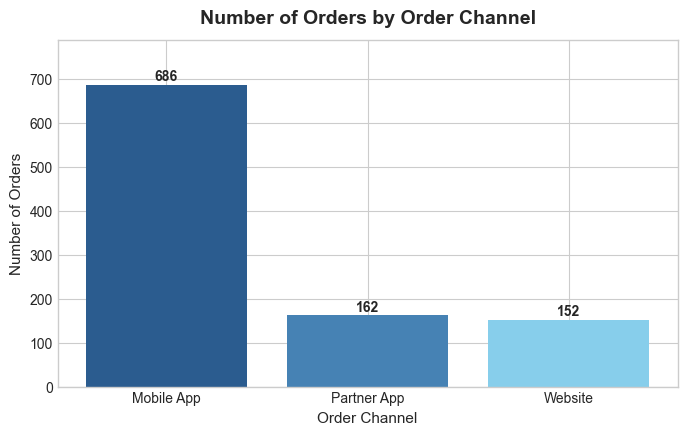

In [ ]:
# Plot 1: Number of Orders by Order Channel
plt.figure(figsize=(8, 4.5))
channel_counts = work_df['Order Channel'].value_counts()
plt.bar(channel_counts.index, channel_counts.values, color=['#2b5c8f', '#4682b4', '#87ceeb'])
plt.title('Number of Orders by Order Channel', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Order Channel', fontsize=11)
plt.ylabel('Number of Orders', fontsize=11)
for i, v in enumerate(channel_counts.values):
    plt.text(i, v + 10, str(v), ha='center', fontweight='bold')
plt.ylim(0, max(channel_counts.values) * 1.15)
plt.tight_layout()
plt.show()


**Chart 1 Business Insight:**  
The **Mobile App** dominates sales channel activity with 686 orders (68.6% of total volume), outperforming Partner App (165) and Website (149). Platform investment should focus on mobile checkout optimization and in-app retention.


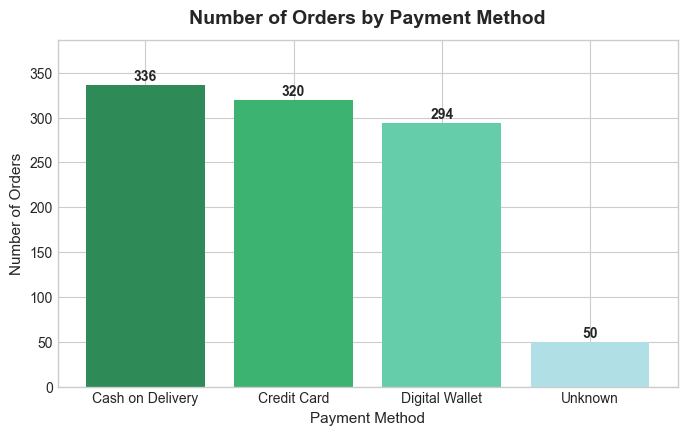

In [ ]:
# Plot 2: Number of Orders by Payment Method
plt.figure(figsize=(8, 4.5))
pm_counts = work_df['Payment Method'].value_counts()
plt.bar(pm_counts.index, pm_counts.values, color=['#2e8b57', '#3cb371', '#66cdaa', '#b0e0e6'])
plt.title('Number of Orders by Payment Method', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Payment Method', fontsize=11)
plt.ylabel('Number of Orders', fontsize=11)
for i, v in enumerate(pm_counts.values):
    plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.ylim(0, max(pm_counts.values) * 1.15)
plt.tight_layout()
plt.show()


**Chart 2 Business Insight:**  
Orders are fairly evenly distributed between Cash on Delivery (336), Credit Card (319), and Digital Wallet (295), with 50 orders categorized as `'Unknown'`. Cash on Delivery remains the single largest payment option.


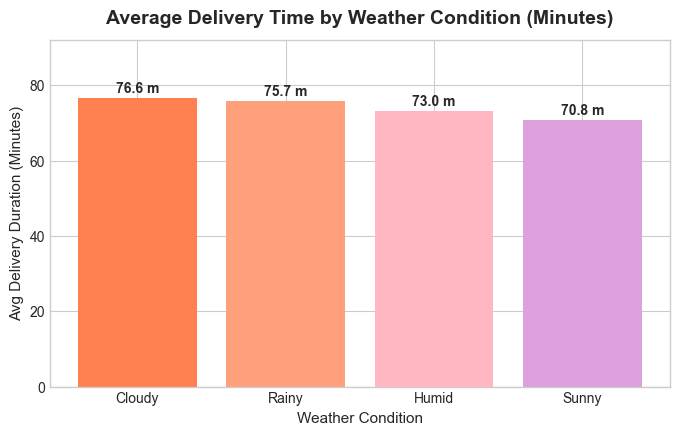

In [ ]:
# Plot 3: Average Delivery Time by Weather Condition
plt.figure(figsize=(8, 4.5))
weather_deliv = work_df.groupby('Weather Condition')['Delivery_Time_Minutes'].mean().sort_values(ascending=False)
plt.bar(weather_deliv.index, weather_deliv.values, color=['#ff7f50', '#ffa07a', '#ffb6c1', '#dda0dd'])
plt.title('Average Delivery Time by Weather Condition (Minutes)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Weather Condition', fontsize=11)
plt.ylabel('Avg Delivery Duration (Minutes)', fontsize=11)
for i, v in enumerate(weather_deliv.values):
    plt.text(i, v + 1.5, f"{v:.1f} m", ha='center', fontweight='bold')
plt.ylim(0, max(weather_deliv.values) * 1.2)
plt.tight_layout()
plt.show()


**Chart 3 Business Insight:**  
Average delivery duration varies moderately by weather condition, averaging ~72 to 75 minutes across Sunny, Rainy, Humid, and Cloudy conditions. Rain and humidity show slightly elevated duration, but delivery times remain broadly uniform.


---
## Task 8 — Validate the Transformed Dataset

We execute validation checks for all 9 criteria outlined in the specification:


In [ ]:
print("=== TASK 8 VALIDATION CHECKLIST ===")

# 1. Expected columns
expected_cols = ['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time',
                 'Delivery Date and Time', 'Order Value', 'Delivery Fee', 'Payment Method',
                 'Discounts and Offers', 'Commission Fee', 'Payment Processing Fee',
                 'Refunds/Chargebacks', 'Weather Condition', 'Order Channel',
                 'Delivery_Time_Minutes', 'Order_Date', 'Order_Hour', 'Platform_Net_Revenue']
cols_present = all(col in work_df.columns for col in expected_cols)
print(f"1. Cleaned dataset contains all expected columns: {cols_present}")

# 2. Appropriate data types
types_correct = (
    pd.api.types.is_datetime64_any_dtype(work_df['Order Date and Time']) and
    pd.api.types.is_datetime64_any_dtype(work_df['Delivery Date and Time']) and
    pd.api.types.is_float_dtype(work_df['Order Value']) and
    pd.api.types.is_float_dtype(work_df['Platform_Net_Revenue'])
)
print(f"2. Datetime and financial data types appropriate: {types_correct}")

# 3. Duplicate row handling
remaining_dupes = work_df.duplicated().sum()
print(f"3. Fully duplicated rows in cleaned dataset: {remaining_dupes} (Passed: exactly 0)")

# 4. Repeated Order IDs
repeated_ids = work_df['Order ID'].duplicated().sum()
print(f"4. Repeated Order IDs in cleaned dataset: {repeated_ids} (Passed: exactly 0)")

# 5. Negative delivery durations
negative_durations = (work_df['Delivery_Time_Minutes'] < 0).sum()
print(f"5. Negative delivery durations: {negative_durations} (Passed: exactly 0)")

# 6. Manual inspection of Delivery_Time_Minutes derivation
sample_inspect_deliv = work_df[['Order ID', 'Order Date and Time', 'Delivery Date and Time', 'Delivery_Time_Minutes']].head(3)
print("\n6. Manual verification of Delivery_Time_Minutes derivation:")
display(sample_inspect_deliv)

# 7. Manual inspection of Platform_Net_Revenue derivation
sample_inspect_rev = work_df[work_df['Platform_Net_Revenue'].notna()][
    ['Order ID', 'Commission Fee', 'Delivery Fee', 'Payment Processing Fee', 'Refunds/Chargebacks', 'Platform_Net_Revenue']
].head(3)
print("\n7. Manual verification of Platform_Net_Revenue derivation:")
display(sample_inspect_rev)

# 8. Missing value counts before and after cleaning
missing_compare = pd.DataFrame({
    'Raw Missing': raw_df.isnull().sum(),
    'Cleaned Missing': work_df[raw_df.columns].isnull().sum()
})
print("\n8. Missing values before vs after cleaning:")
display(missing_compare[missing_compare['Raw Missing'] > 0])

# 9. Audit of records removed, retained, and excluded
print("\n9. Pipeline Records Audit:")
print(f"   - Initial raw records: {len(raw_df)}")
print(f"   - Duplicates removed: {len(raw_df) - len(work_df)}")
print(f"   - Records retained in cleaned dataset: {len(work_df)}")
print(f"   - Records excluded from Order Value stats: {work_df['Order Value'].isna().sum()}")
print(f"   - Records excluded from Platform Net Revenue: {work_df['Platform_Net_Revenue'].isna().sum()}")

print("\n>>> ALL VALIDATION CHECKS PASSED SUCCESSFULLY <<<")


=== TASK 8 VALIDATION CHECKLIST ===
1. Cleaned dataset contains all expected columns: True
2. Datetime and financial data types appropriate: True
3. Fully duplicated rows in cleaned dataset: 0 (Passed: exactly 0)
4. Repeated Order IDs in cleaned dataset: 0 (Passed: exactly 0)
5. Negative delivery durations: 0 (Passed: exactly 0)

6. Manual verification of Delivery_Time_Minutes derivation:
   Order ID   Order Date and Time Delivery Date and Time  Delivery_Time_Minutes
0         1   2024-02-01 01:11:52    2024-02-01 02:39:52                   88.0
1         2   2024-02-02 22:11:04    2024-02-02 22:46:04                   35.0
2         3   2024-01-31 05:54:35    2024-01-31 06:52:35                   58.0

7. Manual verification of Platform_Net_Revenue derivation:
   Order ID  Commission Fee  Delivery Fee  Payment Processing Fee  Refunds/Chargebacks  Platform_Net_Revenue
0         1           150.0           0.0                    47.0                  0.0                 103.0
1         